# 01 · Exploração das avaliações da Olist

Objetivo: entender o texto das avaliações antes de montar a base de conhecimento. Cada achado aqui vira uma decisão em `src/preprocessing/base_conhecimento.py`, e a tabela no fim liga achado a decisão.

Pré-requisito: `python -m src.ingestion.baixar_dados` e `python -m src.preprocessing.base_conhecimento` e `python -m src.temas.temas`.

In [1]:
import os, sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ)); os.chdir(RAIZ)

import pandas as pd
import matplotlib.pyplot as plt
from src import config

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, VERMELHO, CINZA = "#2a7ab9", "#c0392b", "#9aa4ad"
reviews = pd.read_csv(config.DADOS_BRUTOS / "olist_order_reviews_dataset.csv")
docs = pd.read_parquet(config.DOCUMENTOS)
reviews.shape, docs.shape

((99224, 7), (36038, 19))

## 1. Quanto da base tem texto?

In [2]:
tem_texto = reviews["review_comment_message"].notna() | reviews["review_comment_title"].notna()
resumo = pd.DataFrame({
    "avaliacoes": reviews.groupby("review_score").size(),
    "com_texto": reviews[tem_texto].groupby("review_score").size(),
})
resumo["%_com_texto"] = (100 * resumo["com_texto"] / resumo["avaliacoes"]).round(1)
print(f"Com algum texto: {tem_texto.sum():,} de {len(reviews):,} ({100*tem_texto.mean():.1f}%)")
resumo

Com algum texto: 42,706 de 99,224 (43.0%)


,avaliacoes,com_texto,%_com_texto
review_score,,,
1,11424,8829,77.3
2,3151,2165,68.7
3,8179,3644,44.6
4,19142,6278,32.8
5,57328,21790,38.0


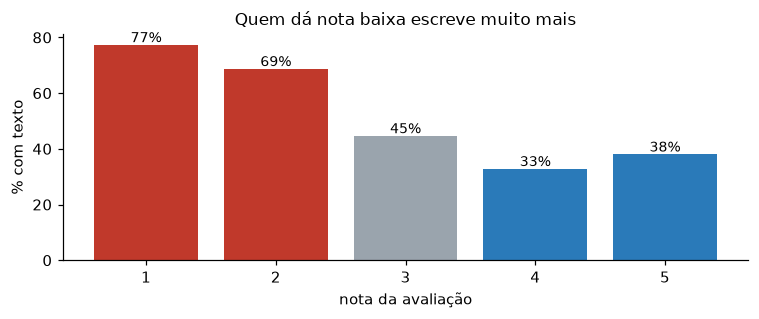

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(resumo.index, resumo["%_com_texto"], color=[VERMELHO, VERMELHO, CINZA, AZUL, AZUL])
for x, v in zip(resumo.index, resumo["%_com_texto"]):
    ax.text(x, v + 1, f"{v:.0f}%", ha="center", fontsize=9)
ax.set_xlabel("nota da avaliação"); ax.set_ylabel("% com texto")
ax.set_title("Quem dá nota baixa escreve muito mais", fontsize=11)
fig.tight_layout(); fig.savefig(config.IMAGENS / "eda_texto_por_nota.png", dpi=150)

**Achado:** a nota 1 tem texto em muito mais casos que a nota 5. A base de texto é enviesada para a insatisfação, então percentuais calculados sobre as avaliações com texto **não** representam todos os clientes. O sistema sempre informa o universo de cada contagem, e o README registra isso como limitação.

## 2. Tamanho dos textos

In [4]:
msg = reviews["review_comment_message"].dropna()
print(msg.str.len().describe().round(0))
print("\nMais comuns:"); print(msg.str.strip().str.lower().value_counts().head(10))

count    40977.0
mean        69.0
std         54.0
min          1.0
25%         28.0
50%         53.0
75%         95.0
max        208.0
Name: review_comment_message, dtype: float64

Mais comuns:
review_comment_message
muito bom        472
bom              342
recomendo        234
otimo            227
ótimo            197
excelente        158
ok               149
tudo ok           93
boa               91
ótimo produto     81
Name: count, dtype: int64


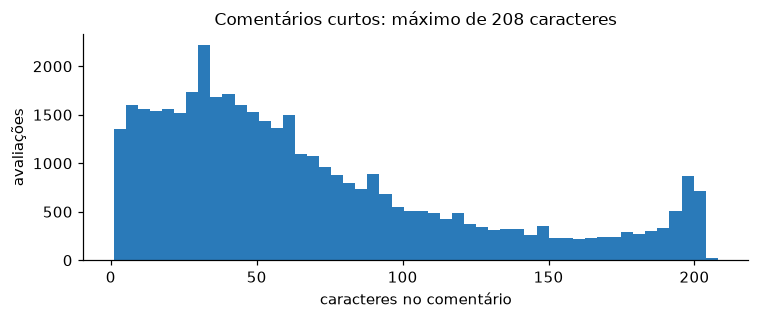

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(msg.str.len(), bins=50, color=AZUL)
ax.set_xlabel("caracteres no comentário"); ax.set_ylabel("avaliações")
ax.set_title("Comentários curtos: máximo de 208 caracteres", fontsize=11)
fig.tight_layout(); fig.savefig(config.IMAGENS / "eda_tamanho_textos.png", dpi=150)

**Achados:** nenhum comentário passa de 208 caracteres, então cada avaliação vira **um documento inteiro, sem chunking**, e a citação aponta a avaliação exata. Os textos mais comuns ("muito bom", "recomendo") não explicam nada: textos com menos de 3 palavras ficam fora do índice, mas a nota deles continua nas estatísticas.

## 3. Funil da base de conhecimento

In [6]:
funil = json.loads(config.FUNIL.read_text(encoding="utf-8"))
pd.DataFrame([(k, v.get("removidas"), v.get("motivo", "")) for k, v in funil.items() if "removidas" in v],
             columns=["etapa", "removidas", "motivo"])

,etapa,removidas,motivo
0,sem_texto,56537,Sem título nem comentário: só a nota. Continua...
1,review_id_repetido,317,O mesmo review_id aparece em mais de um pedido...
2,texto_curto_demais,6332,Menos de 3 palavras: não explicam o porquê da ...


## 4. Entrega e nota

In [7]:
tab = pd.crosstab(docs["status_entrega"], docs["nota"], normalize="index").mul(100).round(1)
tab

nota,1,2,3,4,5
status_entrega,,,,,
atrasado,65.4,9.3,9.4,6.1,9.8
nao_entregue,78.7,8.0,5.8,2.7,4.8
no_prazo,15.5,5.2,9.1,15.6,54.6


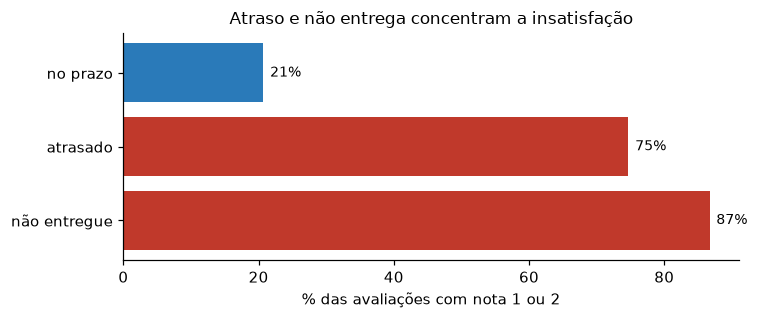

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
ordem = ["no_prazo", "atrasado", "nao_entregue"]
baixa = tab.loc[ordem, [1, 2]].sum(axis=1)
ax.barh(["no prazo", "atrasado", "não entregue"], baixa, color=[AZUL, VERMELHO, VERMELHO])
for y, v in enumerate(baixa):
    ax.text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9)
ax.set_xlabel("% das avaliações com nota 1 ou 2"); ax.invert_yaxis()
ax.set_title("Atraso e não entrega concentram a insatisfação", fontsize=11)
fig.tight_layout(); fig.savefig(config.IMAGENS / "eda_entrega_nota.png", dpi=150)

**Achado:** o status de entrega separa bem satisfeitos e insatisfeitos. Por isso ele virou metadado filtrável (`status_entrega`), calculado da data real × data estimada de entrega.

## 5. Temas por nota

In [9]:
from src.temas.temas import TEMAS
base = docs.merge(pd.read_parquet(config.TEMAS), on="review_id")
nomes = {t.nome: t.rotulo for t in TEMAS}
por_nota = base.groupby("nota")[[t.nome for t in TEMAS]].mean().mul(100).round(1).T.rename(index=nomes)
por_nota

nota,1,2,3,4,5
Atraso na entrega,13.3,14.1,10.7,5.2,1.2
Produto não entregue,35.6,20.4,12.9,2.9,0.8
Pedido incompleto,10.8,11.9,8.3,2.0,0.3
Produto errado ou diferente do anunciado,6.2,4.8,3.8,1.0,0.2
Defeito ou avaria,7.4,9.6,7.0,3.2,0.6
Qualidade ruim,4.7,7.3,4.9,3.7,3.3
Atendimento e falta de retorno,6.1,2.4,1.0,0.4,0.1
"Devolução, troca ou reembolso",16.0,9.2,6.4,2.1,0.6
Embalagem,2.0,3.4,4.0,4.3,4.5
Preço ou frete,4.0,5.7,6.9,6.0,4.5


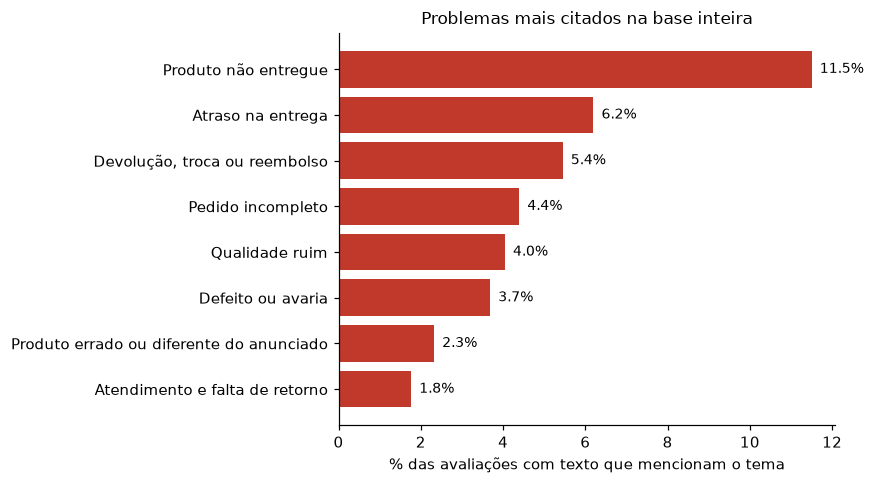

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
problemas = [t.nome for t in TEMAS if t.tipo == "problema"]
geral = base[problemas].mean().mul(100).sort_values()
ax.barh([nomes[n] for n in geral.index], geral.values, color=VERMELHO)
for y, v in enumerate(geral.values):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("% das avaliações com texto que mencionam o tema")
ax.set_title("Problemas mais citados na base inteira", fontsize=11)
fig.tight_layout(); fig.savefig(config.IMAGENS / "eda_temas_problemas.png", dpi=150)

## 6. Achados e decisões

| Achado | Decisão |
|---|---|
| 43% das avaliações têm texto; a nota 1 tem texto muito mais vezes que a 5 | Base de texto enviesada para insatisfação: o universo de cada contagem é sempre informado |
| Comentários de até 208 caracteres | Um documento por avaliação, sem chunking; citação exata |
| Textos mais comuns são "muito bom", "recomendo" | Menos de 3 palavras: fora do índice, nota mantida nas estatísticas |
| O mesmo `review_id` aparece em mais de um pedido | Um documento por `review_id`, para não contar duas vezes |
| Atraso e não entrega concentram as notas baixas | `status_entrega` como metadado filtrável |
| Perguntas de frequência pedem contagem | Classificação de temas na base inteira (`src/temas/temas.py`) |